In [4]:
import sys, joblib
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_predict, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             precision_recall_curve, ConfusionMatrixDisplay)

df = pd.read_csv("../data/WineQT.csv").drop(columns=["Id"])
df["high_quality"] = (df["quality"] >= 7).astype(int)

X = df.drop(columns=["quality", "high_quality"])
y = df["high_quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5],
    "class_weight": ["balanced", "balanced_subsample", None],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor F1 (CV): {grid.best_score_:.3f}")

rf_best = grid.best_estimator_

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 400}
Melhor F1 (CV): 0.641


In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, f1_score

# probabilidades obtidas por validação cruzada — nenhuma amostra prevista
# por um modelo que a viu no treino
y_prob_cv = cross_val_predict(rf_best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, y_prob_cv)
f1_scores = 2 * (prec * rec) / (prec + rec + 1e-9)
melhor_idx = f1_scores[:-1].argmax()
limiar = thr[melhor_idx]

print(f"Limiar ótimo: {limiar:.3f}")
print(f"F1 esperado: {f1_scores[melhor_idx]:.3f} | precisão {prec[melhor_idx]:.3f} | recall {rec[melhor_idx]:.3f}")

Limiar ótimo: 0.605
F1 esperado: 0.645 | precisão 0.597 | recall 0.701


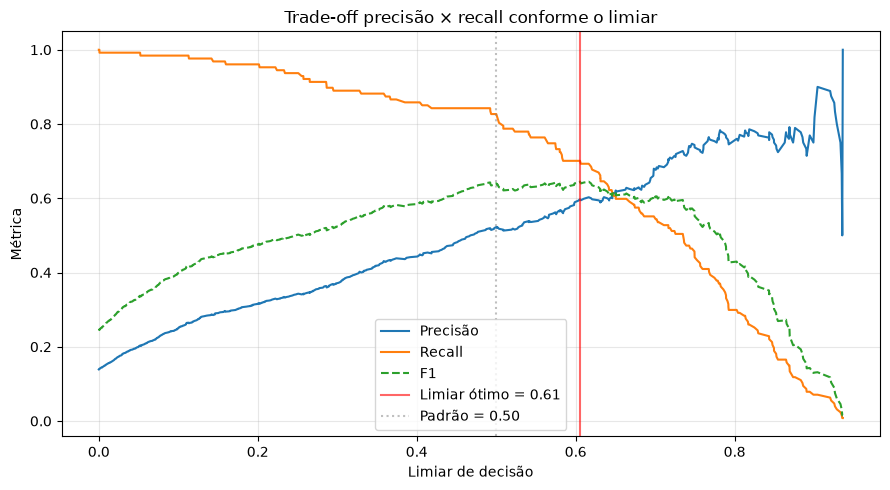

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(thr, prec[:-1], label="Precisão")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1_scores[:-1], label="F1", linestyle="--")
plt.axvline(limiar, color="red", alpha=0.6, label=f"Limiar ótimo = {limiar:.2f}")
plt.axvline(0.5, color="gray", alpha=0.5, linestyle=":", label="Padrão = 0.50")
plt.xlabel("Limiar de decisão"); plt.ylabel("Métrica")
plt.title("Trade-off precisão × recall conforme o limiar")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("../results/05_limiar_decisao.png", dpi=150)
plt.show()

In [8]:
y_prob_test = rf_best.predict_proba(X_test)[:, 1]

for nome, pred in [("Limiar padrão (0.50)", (y_prob_test >= 0.5).astype(int)),
                   (f"Limiar otimizado ({limiar:.2f})", (y_prob_test >= limiar).astype(int))]:
    print(f"\n--- {nome} ---")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=["Baixa/Média", "Alta"], digits=3))

print(f"ROC-AUC (independe do limiar): {roc_auc_score(y_test, y_prob_test):.3f}")


--- Limiar padrão (0.50) ---
[[175  22]
 [ 10  22]]
              precision    recall  f1-score   support

 Baixa/Média      0.946     0.888     0.916       197
        Alta      0.500     0.688     0.579        32

    accuracy                          0.860       229
   macro avg      0.723     0.788     0.748       229
weighted avg      0.884     0.860     0.869       229


--- Limiar otimizado (0.61) ---
[[181  16]
 [ 10  22]]
              precision    recall  f1-score   support

 Baixa/Média      0.948     0.919     0.933       197
        Alta      0.579     0.688     0.629        32

    accuracy                          0.886       229
   macro avg      0.763     0.803     0.781       229
weighted avg      0.896     0.886     0.890       229

ROC-AUC (independe do limiar): 0.892


In [9]:
rf_default = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=42, n_jobs=-1)

for nome, modelo in [("RF padrão", rf_default), ("RF otimizada", rf_best)]:
    f1  = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="f1")
    auc = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{nome:14s} | F1 {f1.mean():.3f} (±{f1.std():.3f}) | AUC {auc.mean():.3f} (±{auc.std():.3f})")

RF padrão      | F1 0.621 (±0.048) | AUC 0.922 (±0.017)
RF otimizada   | F1 0.641 (±0.049) | AUC 0.917 (±0.022)


In [10]:
# treina o modelo final em todos os dados de treino e persiste
rf_final = grid.best_estimator_
rf_final.fit(X_train, y_train)

joblib.dump(
    {"modelo": rf_final, "limiar": float(limiar), "features": list(X.columns)},
    "../models/random_forest.pkl"
)
print("modelo salvo")

modelo salvo


In [11]:
pd.DataFrame({
    "modelo": ["Regressão Logística", "RF padrão", "RF otimizada (limiar 0.61)"],
    "f1_cv_treino": [None, 0.621, 0.641],
    "auc_cv_treino": [None, 0.922, 0.917],
    "f1_teste_alta": [0.489, 0.579, 0.629],
    "precisao_teste_alta": [0.379, 0.500, 0.579],
    "recall_teste_alta": [0.688, 0.688, 0.688],
    "auc_teste": [0.850, None, 0.892],
}).to_csv("../results/metricas_comparacao.csv", index=False)